In [ ]:
загрузка модели

In [1]:
from sentence_transformers import SparseEncoder

model = SparseEncoder("naver/splade-cocondenser-selfdistil")

queries = ["Which planet is known as the Red Planet?"]
documents = [
	"Venus is often called Earth's twin because of its similar size and proximity.",
	"Mars, known for its reddish appearance, is often referred to as the Red Planet.",
	"Jupiter, the largest planet in our solar system, has a prominent red spot.",
]

query_embeddings = model.encode_query(queries)
document_embeddings = model.encode_document(documents)

similarities = model.similarity(query_embeddings, document_embeddings)
print(similarities)

modules.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.92k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

tensor([[ 7.4643, 19.7833, 17.0463]], device='cuda:0')


In [ ]:
данные и кодировка

In [2]:
!pip -q install ir_datasets
import ir_datasets
ds = ir_datasets.load("msmarco-passage/dev/small")
queries = list(ds.queries_iter())      
qrels = list(ds.qrels_iter())          

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.8/947.8 kB 12.6 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.3 MB/s eta 0:00:0000:01


[INFO] Please confirm you agree to the MSMARCO data usage agreement found at <http://www.msmarco.org/dataset.aspx>
[INFO] If you have a local copy of https://msmarco.z22.web.core.windows.net/msmarcoranking/collectionandqueries.tar.gz, you can symlink it here to avoid downloading it again: /root/.ir_datasets/downloads/31644046b18952c1386cd4564ba2ae69
[INFO] [starting] https://msmarco.z22.web.core.windows.net/msmarcoranking/collectionandqueries.tar.gz
[INFO] [finished] https://msmarco.z22.web.core.windows.net/msmarcoranking/collectionandqueries.tar.gz: [01:20] [1.06GB] [13.2MB/s]


In [4]:
!pip -q install ir_datasets
import ir_datasets, random, json
random.seed(0)

ds_q = ir_datasets.load("msmarco-passage/dev/small")
all_queries = list(ds_q.queries_iter())
random.shuffle(all_queries)
queries = all_queries[:200]
qids = {q.query_id for q in queries}

qrels = {}                                   
for r in ds_q.qrels_iter():
    if r.query_id in qids and r.relevance > 0:
        qrels.setdefault(r.query_id, set()).add(r.doc_id)
relevant = set().union(*qrels.values())
print(len(queries), "запросов,", len(relevant), "релевантных пассажей")


N_DISTRACT = 20000
docs = ir_datasets.load("msmarco-passage")
rel_texts, other = {}, []
for d in docs.docs_iter():
    if d.doc_id in relevant:
        rel_texts[d.doc_id] = d.text
    elif len(other) < N_DISTRACT:
        other.append((d.doc_id, d.text))
    if len(other) >= N_DISTRACT and len(rel_texts) == len(relevant):
        break

doc_ids_list = list(rel_texts) + [i for i, _ in other]
doc_texts    = list(rel_texts.values()) + [t for _, t in other]
query_ids_list = [q.query_id for q in queries]
query_texts    = [q.text for q in queries]
print(len(doc_texts), "пассажей в подвыборке")

[INFO] [starting] fixing encoding


200 запросов, 219 релевантных пассажей


[INFO] [finished] fixing encoding: [10:54] [3.06GB] [4.68MB/s]


20219 пассажей в подвыборке


In [5]:
emb = model.encode_document(doc_texts[:3])
print(type(emb), emb.shape)

<class 'torch.Tensor'> torch.Size([3, 30522])


In [6]:
import numpy as np, scipy.sparse as sp, time

def encode_to_csr(texts, encode_fn, bs=64):
    parts = []
    for i in range(0, len(texts), bs):
        emb = encode_fn(texts[i:i + bs])
        if hasattr(emb, "to_dense"):
            emb = emb.to_dense()
        x = emb.cpu().numpy() if hasattr(emb, "cpu") else np.asarray(emb)
        parts.append(sp.csr_matrix(x))
    return sp.vstack(parts).tocsr()


t0 = time.time()
_ = encode_to_csr(doc_texts[:1000], model.encode_document)
dt = time.time() - t0
print(f"1000 пассажей за {dt:.0f}s -> все {len(doc_texts)} примерно за {dt * len(doc_texts) / 1000 / 60:.0f} мин")

1000 пассажей за 11s -> все 20219 примерно за 4 мин


In [7]:
D = encode_to_csr(doc_texts, model.encode_document)
Q = encode_to_csr(query_texts, model.encode_query)
print(D.shape, Q.shape)
print("nnz/док =", D.nnz / D.shape[0], "| nnz/запрос =", Q.nnz / Q.shape[0])

sp.save_npz("/kaggle/working/D.npz", D)
sp.save_npz("/kaggle/working/Q.npz", Q)
json.dump({"doc_ids": doc_ids_list, "query_ids": query_ids_list,
           "qrels": {k: list(v) for k, v in qrels.items()}},
          open("/kaggle/working/meta.json", "w"))

(20219, 30522) (200, 30522)
nnz/док = 138.62278055294524 | nnz/запрос = 62.115


In [ ]:
posting list

In [8]:
import time
import numba as nb

class PostingIndex:
    def __init__(self, offsets, doc_ids, values, n_docs):
        self.offsets = offsets
        self.doc_ids = doc_ids
        self.values = values
        self.n_docs = n_docs
        self._acc = np.zeros(n_docs, dtype=np.float32)

    @classmethod
    def build(cls, D):
        D = D.tocsr()
        n_docs, V = D.shape
        rows = np.repeat(np.arange(n_docs, dtype=np.int32), np.diff(D.indptr))
        terms = D.indices.astype(np.int64)
        vals = D.data.astype(np.float32)

        order = np.lexsort((rows, terms))       
        doc_ids = rows[order]
        values = vals[order]

        counts = np.bincount(terms, minlength=V)
        offsets = np.zeros(V + 1, dtype=np.int64)
        np.cumsum(counts, out=offsets[1:])
        return cls(offsets, doc_ids, values, n_docs)

    def search(self, q_terms, q_vals, k=10):
        acc = self._acc
        acc.fill(0.0)
        _accumulate(self.offsets, self.doc_ids, self.values,
                    q_terms.astype(np.int64), q_vals.astype(np.float32), acc)
        k = min(k, self.n_docs)
        top = np.argpartition(-acc, k - 1)[:k]
        top = top[np.argsort(-acc[top])]
        return top, acc[top].copy()

@nb.njit(cache=True)
def _accumulate(offsets, doc_ids, values, q_terms, q_vals, acc):
    for i in range(q_terms.size):
        t = q_terms[i]
        w = q_vals[i]
        for p in range(offsets[t], offsets[t + 1]):
            acc[doc_ids[p]] += w * values[p]

In [9]:
t0 = time.time()
index = PostingIndex.build(D)
print(f"build: {time.time()-t0:.1f}s, самый длинный список = {np.diff(index.offsets).max()}")


q0 = Q[0]; index.search(q0.indices, q0.data, 10)


Dt = D.T.tocsr()
bad = 0
for i in range(min(100, Q.shape[0])):
    q = Q[i]
    ids, sc = index.search(q.indices, q.data, 10)
    ref = np.asarray((q @ Dt).todense()).ravel()
    if not np.allclose(sc, np.sort(ref)[::-1][:10], rtol=1e-4, atol=1e-4):
        bad += 1
print("расхождений со scipy:", bad)


lat = []
for i in range(Q.shape[0]):
    q = Q[i]
    t0 = time.perf_counter()
    index.search(q.indices, q.data, 10)
    lat.append((time.perf_counter() - t0) * 1000)
print(f"p50 = {np.percentile(lat,50):.2f} мс, p99 = {np.percentile(lat,99):.2f} мс")

build: 0.3s, самый длинный список = 3851
расхождений со scipy: 0
p50 = 0.24 мс, p99 = 0.50 мс


In [ ]:
проверка качетсва

In [12]:
rr = []
for i, qid in enumerate(query_ids_meta):
    q = Q[i]
    ids, _ = index.search(q.indices, q.data, 10)
    rel = set(qrels_meta[qid])
    got = [doc_ids_meta[d] for d in ids]
    r = next((1.0 / (rank + 1) for rank, x in enumerate(got) if x in rel), 0.0)
    rr.append(r)
    if i < 3:
        print(qid, got[:3], rel, "->", r)

print("MRR@10 =", np.mean(rr), "| запросов с попаданием в топ-10:", sum(x > 0 for x in rr), "из", len(rr))

393696 ['7598745', '7834912', '8131'] {'7598745'} -> 1.0
86264 ['7337466', '18087', '5366'] {'7337466'} -> 1.0
749752 ['7610789', '1618', '5372'] {'7610789'} -> 1.0
MRR@10 = 0.9632142857142857 | запросов с попаданием в топ-10: 199 из 200


In [11]:
i = 0
q = Q[i]
ids, sc = index.search(q.indices, q.data, 3)
print("ЗАПРОС:", query_texts[i], "| qid =", query_ids_meta[i])
print("релевантные id:", qrels_meta[query_ids_meta[i]])

for d, s in zip(ids, sc):
    print(f"\nскор {s:.1f}, doc_id {doc_ids_meta[d]}:", doc_texts[d][:150])

# где лежит релевантный пассаж и какой у него скор
rel_id = qrels_meta[query_ids_meta[i]][0]
row = doc_ids_meta.index(rel_id)
print("\nРЕЛЕВАНТНЫЙ (строка", row, "):", doc_texts[row][:150])
print("его скор:", float(D[row].multiply(q).sum()))

ЗАПРОС: in texas what requirements are needed to apply to become a broker | qid = 393696
релевантные id: ['7598745']

скор 24.2, doc_id 7598745: The Texas State Securities Board has no established educational requirements for becoming a stockbroker, but many broker-dealer firms will require tha

скор 16.9, doc_id 7834912: Pre-Licensing Classes: The Broker Pre-Licensing Course INCLUDES the required textbook and online study materials. The Broker Prelicensing course is th

скор 16.5, doc_id 8131: Registration Requirements. Section 9.001 of the Texas Business Organizations Code (“BOC”) requires the following types of foreign entities to file an 

РЕЛЕВАНТНЫЙ (строка 139 ): The Texas State Securities Board has no established educational requirements for becoming a stockbroker, but many broker-dealer firms will require tha
его скор: 24.19489097595215


In [ ]:
import json
meta = json.load(open("/kaggle/working/meta.json"))
doc_ids_meta, query_ids_meta, qrels_meta = meta["doc_ids"], meta["query_ids"], meta["qrels"]

In [13]:
exact_top = [index.search(Q[i].indices, Q[i].data, 10)[0] for i in range(Q.shape[0])]

In [14]:
!pip -q install pyseismic-lsr
from seismic import SeismicIndex, get_seismic_string
print("ok")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 6.4 MB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ok


In [15]:
import json
vocab = model.tokenizer.convert_ids_to_tokens(list(range(D.shape[1])))

with open("/kaggle/working/docs.jsonl", "w") as f:
    for i in range(D.shape[0]):
        s, e = D.indptr[i], D.indptr[i + 1]
        vec = {vocab[int(t)]: float(v) for t, v in zip(D.indices[s:e], D.data[s:e])}
        f.write(json.dumps({"id": i, "vector": vec}) + "\n")
print("exported", D.shape[0])

exported 20219


In [19]:
t0 = time.time()
sindex = SeismicIndex.build("/kaggle/working/docs.jsonl")
print(f"build: {time.time()-t0:.1f}s | docs = {sindex.len} | nnz/док = {sindex.nnz / sindex.len:.0f}")

string_type = get_seismic_string()
q = Q[0]
comps = np.array([vocab[int(t)] for t in q.indices], dtype=string_type)
vals = q.data.astype(np.float32)

res = sindex.search(query_id="0", query_components=comps, query_values=vals,
                    k=10, query_cut=10, heap_factor=0.7)
print(res)
print("эталон:", exact_top[0])


Building the index...
Configuration { pruning: GlobalThreshold { n_postings: 3500, max_fraction: 1.5 }, blocking: RandomKmeans { centroid_fraction: 0.1, min_cluster_size: 2, clustering_algorithm: RandomKmeansInvertedIndexApprox { doc_cut: 15 } }, summarization: EnergyPreserving { summary_energy: 0.4 }, knn: KnnConfiguration { nknn: 0, knn_path: None } }
Reading the collection..
build: 22.1s | docs = 20219 | nnz/док = 139
[('0', 24.195411682128906, '139'), ('0', 16.940643310546875, '178'), ('0', 16.48397445678711, '8350'), ('0', 14.556941986083984, '9715'), ('0', 13.006223678588867, '8345'), ('0', 11.921111106872559, '9714'), ('0', 11.895233154296875, '9719'), ('0', 11.773362159729004, '1808'), ('0', 11.56387996673584, '8039'), ('0', 11.322514533996582, '2041')]
эталон: [ 139  178 8350 9715 8345 9714 9719 1808 8039 2041]
Number of rows: 20219
Elapsed time to read the collection: 2 secs
Distributing and pruning postings: 0 secs
Number of posting lists: 25468
Avg posting list length: 110

In [20]:
q_comps = [np.array([vocab[int(t)] for t in Q[i].indices], dtype=string_type) for i in range(Q.shape[0])]
q_vals  = [Q[i].data.astype(np.float32) for i in range(Q.shape[0])]
q_idx   = [Q[i].indices for i in range(Q.shape[0])]
q_dat   = [Q[i].data for i in range(Q.shape[0])]

def mrr_of(ids, i):
    rel = set(qrels_meta[query_ids_meta[i]])
    return next((1.0 / (r + 1) for r, d in enumerate(ids) if doc_ids_meta[d] in rel), 0.0)

def run_exact(k=10):
    lat, rr = [], []
    for i in range(Q.shape[0]):
        t0 = time.perf_counter()
        ids, _ = index.search(q_idx[i], q_dat[i], k)
        lat.append((time.perf_counter() - t0) * 1000)
        rr.append(mrr_of(ids.tolist(), i))
    return np.percentile(lat, 50), np.percentile(lat, 99), 1.0, np.mean(rr)

def run_seismic(qc, hf, k=10):
    lat, rec, rr = [], [], []
    for i in range(Q.shape[0]):
        t0 = time.perf_counter()
        res = sindex.search(query_id=str(i), query_components=q_comps[i], query_values=q_vals[i],
                            k=k, query_cut=qc, heap_factor=hf)
        lat.append((time.perf_counter() - t0) * 1000)
        ids = [int(x[2]) for x in res]
        rec.append(len(set(ids) & set(exact_top[i].tolist())) / k)
        rr.append(mrr_of(ids, i))
    return np.percentile(lat, 50), np.percentile(lat, 99), np.mean(rec), np.mean(rr)

print(f"{'метод':<28}{'p50 мс':>8}{'p99 мс':>8}{'recall@10':>11}{'MRR@10':>8}")
p50, p99, rec, mrr = run_exact()
print(f"{'точный (твой)':<28}{p50:>8.2f}{p99:>8.2f}{rec:>11.3f}{mrr:>8.3f}")
for qc in [3, 5, 10, 20, 40]:
    for hf in [0.5, 0.7, 0.9]:
        p50, p99, rec, mrr = run_seismic(qc, hf)
        print(f"{'seismic cut=%d hf=%.1f' % (qc, hf):<28}{p50:>8.2f}{p99:>8.2f}{rec:>11.3f}{mrr:>8.3f}")

метод                         p50 мс  p99 мс  recall@10  MRR@10
точный (твой)                   0.23    0.42      1.000   0.963
seismic cut=3 hf=0.5            0.33    0.84      0.947   0.963
seismic cut=3 hf=0.7            0.25    0.52      0.933   0.963
seismic cut=3 hf=0.9            0.19    0.40      0.901   0.963
seismic cut=5 hf=0.5            0.51    1.07      0.992   0.963
seismic cut=5 hf=0.7            0.37    0.71      0.978   0.963
seismic cut=5 hf=0.9            0.26    0.49      0.959   0.963
seismic cut=10 hf=0.5           0.87    1.57      0.999   0.963
seismic cut=10 hf=0.7           0.60    1.04      0.996   0.963
seismic cut=10 hf=0.9           0.44    0.75      0.988   0.963
seismic cut=20 hf=0.5           1.43    2.48      1.000   0.963
seismic cut=20 hf=0.7           1.04    1.73      0.999   0.963
seismic cut=20 hf=0.9           0.72    1.19      0.997   0.963
seismic cut=40 hf=0.5           2.38    4.02      1.000   0.963
seismic cut=40 hf=0.7           1.62    

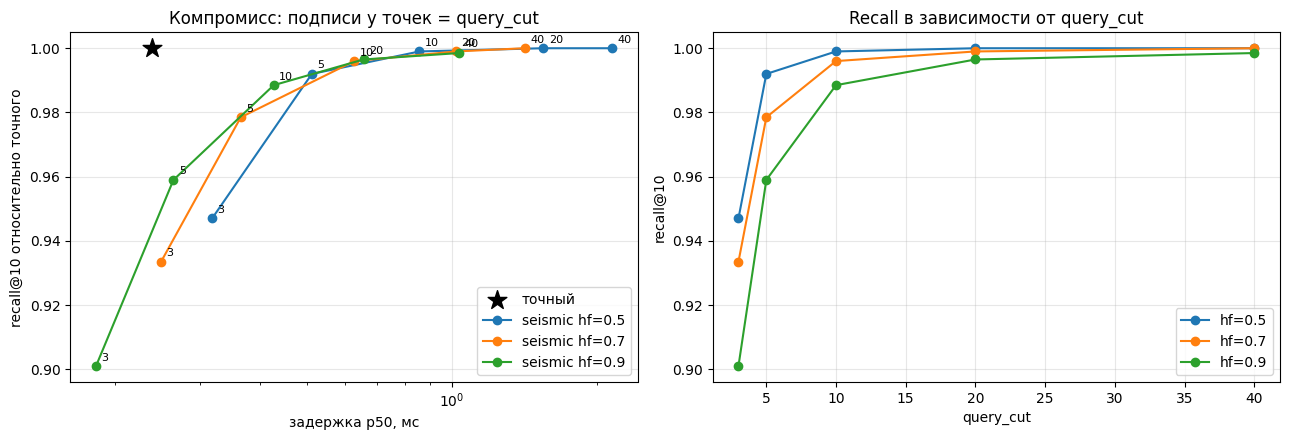

In [21]:
import matplotlib.pyplot as plt

rows = [] 
p50, p99, rec, mrr = run_exact()
rows.append(("exact", None, None, p50, p99, rec, mrr))
for qc in [3, 5, 10, 20, 40]:
    for hf in [0.5, 0.7, 0.9]:
        p50, p99, rec, mrr = run_seismic(qc, hf)
        rows.append(("seismic", qc, hf, p50, p99, rec, mrr))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))


ex = rows[0]
ax[0].scatter(ex[3], ex[5], marker="*", s=200, color="black", label="точный", zorder=3)
for hf in [0.5, 0.7, 0.9]:
    pts = [r for r in rows if r[0] == "seismic" and r[2] == hf]
    ax[0].plot([r[3] for r in pts], [r[5] for r in pts], marker="o", label=f"seismic hf={hf}")
    for r in pts:
        ax[0].annotate(str(r[1]), (r[3], r[5]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[0].set_xscale("log")
ax[0].set_xlabel("задержка p50, мс"); ax[0].set_ylabel("recall@10 относительно точного")
ax[0].set_title("Компромисс: подписи у точек = query_cut"); ax[0].legend(); ax[0].grid(alpha=0.3)

# 2) Recall против query_cut
for hf in [0.5, 0.7, 0.9]:
    pts = [r for r in rows if r[0] == "seismic" and r[2] == hf]
    ax[1].plot([r[1] for r in pts], [r[5] for r in pts], marker="o", label=f"hf={hf}")
ax[1].set_xlabel("query_cut"); ax[1].set_ylabel("recall@10")
ax[1].set_title("Recall в зависимости от query_cut"); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/pareto.png", dpi=150)
plt.show()

На подвыборке из 20k пассажей точный поиск по обратному индексу работает за 0.23 ,приближённый Seismic не быстрее при потере качества. Для  top-10 достаточно малой доли координат запроса, на моем количестве выборки сложно сравнивать